This notebook analyses the data previously published by [Thévenot et al. (2015)](https://doi.org/10.1021/acs.jproteome.5b00354) based on the work described in [Mendez et al. (2019)](https://doi.org/10.1007/s11306-019-1612-4).
The data was made "dirty" and then "cleaned" with different imputation strategies.

This notebook was written by Nikolai Egorov

# 1. Import Packages

In [36]:
import os
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import roc_curve, auc, accuracy_score
from sklearn.preprocessing import StandardScaler

print('All packages successfully loaded')

All packages successfully loaded


## 2. Load Data & Peak Sheet

In [37]:
raw_url = 'https://raw.githubusercontent.com/CIMCB/MetabComparisonBinaryML/master/notebooks/data/MTBLS90.xlsx'

if not os.path.exists('../data/MTBLS90.xlsx'):
    # Download the file
    response = requests.get(raw_url)
    with open('../data/MTBLS90.xlsx', 'wb') as f:
        f.write(response.content)

DataTable = pd.read_excel('../data/MTBLS90.xlsx', sheet_name='Data')
PeakTable = pd.read_excel('../data/MTBLS90.xlsx', sheet_name='Peak')

C:\Users\egoro\Documents\mlails-2025\venv\Lib\site-packages\openpyxl\worksheet\_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)
C:\Users\egoro\Documents\mlails-2025\venv\Lib\site-packages\openpyxl\worksheet\_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)


## 3. Extract X & Y

In [38]:
# Extract PeakList
PeakList = PeakTable['Name']

# Select Subset of Data
DataTable2 = DataTable[(DataTable.Class == 1) | (DataTable.Class == 0)]

Y = DataTable2['Class'].values

# Split Data into Train (2/3) and Test (1/3)
DataTrain, DataTest, YTrain, YTest = train_test_split(DataTable2, Y, test_size=1/3, stratify=Y, random_state=8)

# Extract and Preprocess Train Data
XTrain = DataTrain[PeakList]
XTrainLog = np.log(XTrain)

# Scale data using StandardScaler
scaler = StandardScaler()
XTrainScale = scaler.fit_transform(XTrainLog)

# Extract and Preprocess Test Data
XTest = DataTest[PeakList]
XTestLog = np.log(XTest)

# Scale test data using the same scaler fitted on training data
XTestScale = scaler.transform(XTestLog)

## 4. Hyperparameters Optimisation

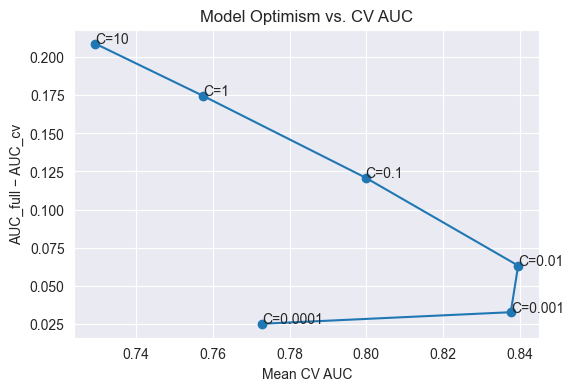

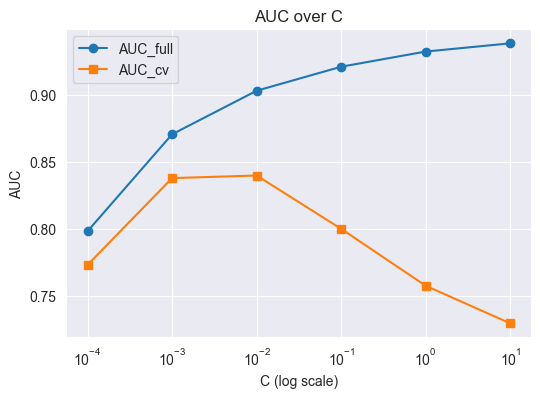

In [39]:
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score

# Our data
X = XTrainScale
y = YTrain

# Parameter grid
C_range = [0.0001, 0.001, 0.01, 0.1, 1, 10]
param_grid = {'C': C_range}

# Initialize KFold cross-validator
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=8)

# Storage
auc_cv = []
auc_full = []

for C in C_range:
    # 1) Cross‐validated AUC
    model = SVC(C=C, kernel='linear', probability=True, random_state=8)
    scores = cross_val_score(model, X, y,
                             cv=cv,
                             scoring='roc_auc',
                             n_jobs=-1)
    # Save mean AUC score for all CV iterations 
    auc_cv.append(scores.mean())
    
    # 2) Train on full data and compute full AUC (score on the whole train data)
    model.fit(X, y)
    y_proba = model.predict_proba(X)[:, 1]
    auc_full.append(roc_auc_score(y, y_proba))

# Save the data for plots
auc_cv = np.array(auc_cv)
auc_full = np.array(auc_full)
auc_diff = auc_full - auc_cv

# === Plot 1: (AUCfull - AUCcv) vs. AUCcv ===
plt.figure(figsize=(6,4))
plt.plot(auc_cv, auc_diff, marker='o', linestyle='-')
for i, C in enumerate(C_range):
    plt.annotate(f"C={C}", (auc_cv[i], auc_diff[i]))
plt.xlabel("Mean CV AUC")
plt.ylabel("AUC_full − AUC_cv")
plt.title("Model Optimism vs. CV AUC")
plt.grid(True)

# === Plot 2: AUCfull & AUCcv vs. C ===
plt.figure(figsize=(6,4))
plt.plot(C_range, auc_full, marker='o', label='AUC_full')
plt.plot(C_range, auc_cv,   marker='s', label='AUC_cv')
plt.xscale('log')
plt.xlabel("C (log scale)")
plt.ylabel("AUC")
plt.title("AUC over C")
plt.legend()
plt.grid(True)

plt.show()

## 5. Build Model & Evaluate

Best C = 0.01 with mean CV AUC = 0.840
Training Accuracy: 0.8512
Test Accuracy: 0.7802


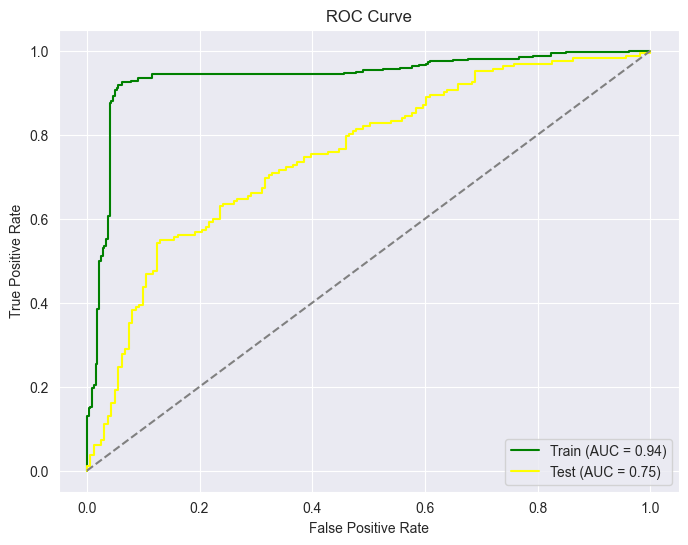

  Dataset  Accuracy       AUC
0   Train  0.851163  0.938177
1    Test  0.780186  0.752205


In [40]:
# 1. Build Model

best_idx   = np.argmax(auc_cv)
best_C     = C_range[best_idx]
best_score = auc_cv[best_idx]

print(f"Best C = {best_C} with mean CV AUC = {best_score:.3f}")

# get the final model:
best_model = SVC(C=best_C, kernel='linear', probability=True, random_state=8)
best_model.fit(XTrainScale, YTrain)  # Train the model

# 2. Predictions
YPredTrain = best_model.predict(XTrainScale)  # Predictions on training data
YPredTest = best_model.predict(XTestScale)  # Predictions on test data

# 3. Evaluation
# Accuracy
train_accuracy = accuracy_score(YTrain, YPredTrain)
test_accuracy = accuracy_score(YTest, YPredTest)
print(f"Training Accuracy: {train_accuracy:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

# ROC Curve
# Get decision function scores for training and test sets
YTrainScores = model.decision_function(XTrainScale)
YTestScores = model.decision_function(XTestScale)

# Calculate ROC curve and AUC
train_fpr, train_tpr, _ = roc_curve(YTrain, YTrainScores)
test_fpr, test_tpr, _ = roc_curve(YTest, YTestScores)
train_auc = auc(train_fpr, train_tpr)
test_auc = auc(test_fpr, test_tpr)

# Plot ROC curve
plt.figure(figsize=(8, 6))
plt.plot(train_fpr, train_tpr, color='green', label=f'Train (AUC = {train_auc:.2f})')
plt.plot(test_fpr, test_tpr, color='yellow', label=f'Test (AUC = {test_auc:.2f})')
plt.plot([0, 1], [0, 1], color='grey', linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.grid(True)
plt.show()

# collect into a dict
results = {
    'Dataset': ['Train', 'Test'],
    'Accuracy': [train_accuracy, test_accuracy],
    'AUC':      [train_auc,      test_auc]
}

# build and show the table
df_results = pd.DataFrame(results)
print(df_results)

## 6. Extract important features

In [41]:
# build a dict for fast lookup
id_to_name = dict(zip(PeakTable['Name'], PeakTable['Label']))

# Compute feature importances
weights = best_model.coef_.ravel()
feature_ids = (
    XTrainScale.columns 
    if hasattr(XTrainScale, 'columns') 
    else [f"M{i}" for i in range(len(weights))]
)
imp = pd.Series(np.abs(weights), index=feature_ids)

# Get top-N by absolute weight
N = 3
topN = imp.sort_values(ascending=False).head(N)
topN.index = [id_to_name.get(fid, fid) for fid in topN.index]

print(f"Top {N} metabolites by |weight|:\n", topN)

Top 3 metabolites by |weight|:
 Theobromine                                               0.197276
Choline                                                   0.193490
Ceramide phosphoethanolamine(35:2)|Sphingomyelin(32:2)    0.184197
dtype: float64
